In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Granularity:
we have 2381 students per row


In [3]:
student_data_df = pd.read_excel('Case Assignment - Sr Associate - Philippines - data.xlsx')
student_data_df.rename(columns={'competency_quiz_score_1': 'Competency_quiz_score_1'}, inplace=True)

In [4]:
# get all possible columns
student_columns = [
    "student_id",
    "user_state_name",
    "user_city_name",
    "user_district_name",
    "user_registartion_date",
    "real_degree",
    "real_institutename",
]

course_columns = [
    "course_id",
    "course_name",
    "course_duration_hours",
    "hours_week",
    "total_of_quizzes_incourse",
    "total_lessons_in_course",
]

batch_columns = [
    "batch_id",
    "batch_name",
    "faculty_id",
    "batch_created_date",
    "batch_start_date",
    "batch_end_date",
    "batch_updatedate",
    "batch_joined_date",
    "batch_status",
]

enrollment_columns = [
    "student_status_inbatch",
    "first_course_enrollment_date",
    "number_of_active_students",
    "total_number_student_enrolled",
]

assessment_columns = [
    "last_quiz_attempt_date",
    "number_of_quiztaken",
    "average_quiz_score",
]

learning_progress_columns = [
    "total_lessons_completed_in_course",
    "lessons_average_score_in_course",
    "student_journey",
    "Pos_Last_visited_status",
]

# competency quizzes columns
competency_name_lists = [f"Competency_name_{i}" for i in range(1, 15)]
competency_quiz_submit_lists = [f"Competency_quiz_submit_{i}" for i in range(1, 15)]
competency_quiz_score_lists = [f"Competency_quiz_score_{i}" for i in range(1, 15)]
competency_quizzes = competency_name_lists + competency_quiz_submit_lists + competency_quiz_score_lists

# combine 
all_columns = (
    student_columns 
    + course_columns
    + batch_columns
    + enrollment_columns
    +  assessment_columns
    + learning_progress_columns
    + competency_quizzes
)

# this is not in the overall columns since if i were to include it, it would overlap
temp_date_columns = [
    "user_registartion_date",
    "actual_graduationdate",
    "employment_startdate",
    "batch_joined_date",
    "batch_created_date",
    "batch_start_date",
    "batch_end_date",
    "batch_updatedate",
    "last_quiz_attempt_date",
    "first_course_enrollment_date",
    "expected_placement_eligible_date",
]
date_columns = temp_date_columns + competency_quiz_submit_lists

In [5]:
identifier_columns = [
    "student_id",
    "course_id",
    "batch_id",
    "faculty_id",
    "real_institutename",
]

risk_predictor_columns = [
    # Enrollment and timing
    "user_registartion_date",
    "first_course_enrollment_date",
    "batch_joined_date",
    "batch_start_date",
    "batch_end_date",

    # Course workload
    "course_duration_hours",
    "hours_week",
    "total_of_quizzes_incourse",
    "total_lessons_in_course",

    # Assessment engagement
    "last_quiz_attempt_date",
    "number_of_quiztaken",
    "average_quiz_score",

    # Learning progress
    "total_lessons_completed_in_course",
    "lessons_average_score_in_course",
    "student_journey",
    "Pos_Last_visited_status",
]

competency_name_lists = [f"Competency_name_{i}" for i in range(1, 15)]
competency_quiz_submit_lists = [f"Competency_quiz_submit_{i}" for i in range(1, 15)]
competency_quiz_score_lists = [f"Competency_quiz_score_{i}" for i in range(1, 15)]
competency_quizzes = competency_name_lists + competency_quiz_submit_lists + competency_quiz_score_lists

outcome_columns = [
    "student_status_inbatch",
    "is_completed_all_courses",
    "is_transformed_in_all_courses",
    "is_eligible_for_placement",
    "expected_placement_eligible_date",
    "actual_graduationdate",
    "employmentsector",
    "employment_startdate",
]

# Removing/Dropping Null/Weird Data

be careful with faculty_country_name because for some reason, there is one indian faculty. They were also the only one who had the unique course of Life Skills (Jeevan Kaushal) 2.0. In total, there are two of these rows. Just to maintain integrity of the data (and also because this is mainly a Filipino anlaysis, I plan to remove these two.) they even had totally different quizzes from everyon else.
plan is to just remove those two

2379 -> 2377 (from dropping the two indian kids) -> 2086 (min of at least two quizzes) -> 2048 (they need to be a course with 14 quizzes, not 11)

assumption 1: students generally do the quizzes sequentially (not even necessarily true!)

In [49]:
# remove the two students that have a different course
student_data_df = student_data_df[student_data_df['course_name'] != 'Life Skills (Jeevan Kaushal) 2.0'].copy()
student_data_df = student_data_df.dropna(subset=competency_quiz_submit_lists, thresh=2)

relevants_dates = ['student_id', 'first_course_enrollment_date'] + competency_quiz_submit_lists + competency_quiz_score_lists

# get dates between the quizzes

In [88]:
competency_quiz_time_deltas = {f'Competency_quiz_delta_{i}':[] for i in range(1, 15)}
competency_quiz_time_submits = {f'Competency_quiz_submit_{i}':[] for i in range(1, 15)}
competency_quiz_time_score = {f'Competency_quiz_score_{i}':[] for i in range(1, 15)}

competency_quizzes = {
    **competency_quiz_time_deltas,
    **competency_quiz_time_submits, 
    **competency_quiz_time_score
}

In [172]:
competency_quizzes = []

for _, student_row in student_data_df.iterrows():
    student_quizzes = {
        'student_id': student_row['student_id'],
        'batch_id': student_row['batch_id'],
        'total_of_quizzes_incourse': student_row['total_of_quizzes_incourse'],
        'is_completed_all_courses': student_row['is_completed_all_courses'],
        'average_quiz_score': student_row['average_quiz_score']
    }

    previous_date = student_row['first_course_enrollment_date']
    cumulative_delta = pd.Timedelta(0)

    for i in range(1, 15):
        submit_col = f'Competency_quiz_submit_{i}'
        score_col = f'Competency_quiz_score_{i}'
        delta_col = f'Competency_quiz_delta_{i}'
        cumsum_col = f'Competency_quiz_cumsum_{i}'

        submit_date = student_row[submit_col]
        score = student_row[score_col]

        if pd.notna(submit_date):
            delta = submit_date - previous_date
            cumulative_delta += delta

            student_quizzes[submit_col] = submit_date
            student_quizzes[score_col] = score
            student_quizzes[delta_col] = delta
            student_quizzes[cumsum_col] = cumulative_delta

            previous_date = submit_date

        else:
            student_quizzes[submit_col] = pd.NaT
            student_quizzes[score_col] = None
            student_quizzes[delta_col] = pd.NaT
            student_quizzes[cumsum_col] = pd.NaT

    competency_quizzes.append(student_quizzes)

competency_quizzes_df = pd.DataFrame(competency_quizzes)

it takes an average/median student 3 weeks to do the 14 quiz course.

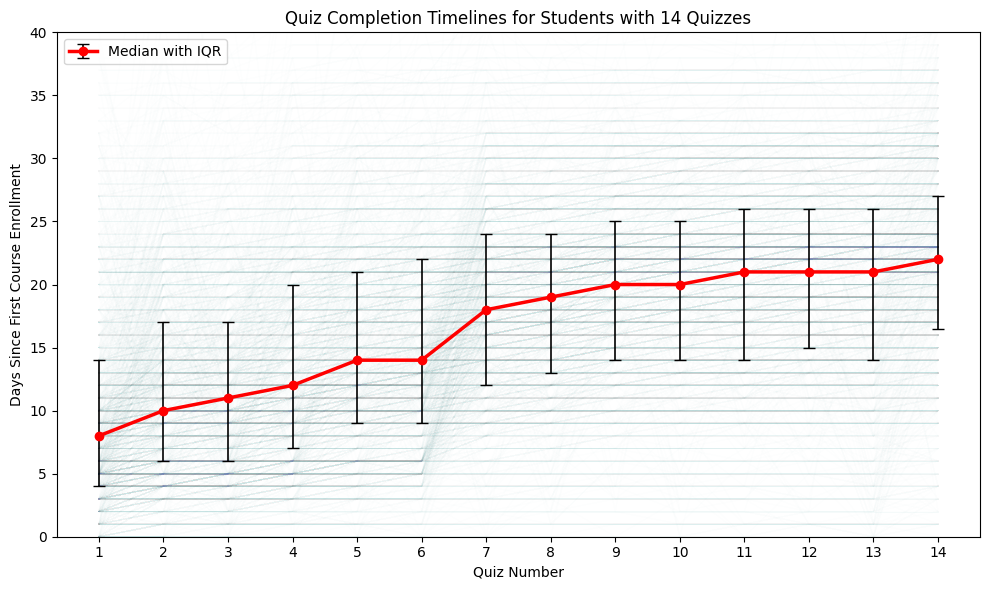

In [173]:
# Filter students who have 14 quizzes in the course.
students_14_quizzes = competency_quizzes_df[
    (competency_quizzes_df['total_of_quizzes_incourse'] == 14)
    & (competency_quizzes_df['is_completed_all_courses'] == 'Y')
]

quiz_delta_cols = list(competency_quiz_time_deltas.keys())

plt.figure(figsize=(10, 6))

all_quiz_days = []

for _, student_row in students_14_quizzes.iterrows():
    quiz_deltas = student_row[quiz_delta_cols].apply(
        lambda x: x.total_seconds() / 86400 if pd.notna(x) else np.nan
    )

    # Cumulative days since enrollment.
    quiz_days = quiz_deltas.cumsum()
    all_quiz_days.append(quiz_days.to_numpy(dtype=float))

    plt.plot(
        range(1, 15),
        quiz_days,
        color='steelblue',
        alpha=0.008,
        linewidth=1
    )

# Calculate median and interquartile range for each quiz.
all_quiz_days = np.array(all_quiz_days)

median_quiz_days = np.nanmedian(all_quiz_days, axis=0)
q25 = np.nanpercentile(all_quiz_days, 25, axis=0)
q75 = np.nanpercentile(all_quiz_days, 75, axis=0)

# Asymmetric error bars: median down to Q1, median up to Q3.
yerr = np.array([
    median_quiz_days - q25,
    q75 - median_quiz_days
])

plt.errorbar(
    range(1, 15),
    median_quiz_days,
    yerr=yerr,
    color='red',
    ecolor='black',
    elinewidth=1.2,
    capsize=4,
    linewidth=2.5,
    marker='o',
    label='Median with IQR'
)

plt.xlabel('Quiz Number')
plt.ylabel('Days Since First Course Enrollment')
plt.ylim(0, 40)
plt.title('Quiz Completion Timelines for Students with 14 Quizzes')
plt.xticks(range(1, 15))
#plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [174]:
for i in range(1, 15):
    delta_col = f'Competency_quiz_delta_{i}'

    valid_data = competency_quizzes_df[
        [delta_col, 'average_quiz_score']
    ].copy()

    valid_data[delta_col] = valid_data[delta_col].dt.total_seconds() / 86400
    valid_data = valid_data.dropna()

    correlation = valid_data[delta_col].corr(
        valid_data['average_quiz_score']
    )
    print(f'Quiz {i}: r = {correlation:.3f}, n = {len(valid_data)}')

Quiz 1: r = -0.134, n = 2080
Quiz 2: r = -0.096, n = 2065
Quiz 3: r = -0.074, n = 2055
Quiz 4: r = -0.039, n = 2034
Quiz 5: r = -0.005, n = 2018
Quiz 6: r = -0.023, n = 2009
Quiz 7: r = 0.018, n = 1993
Quiz 8: r = -0.060, n = 1981
Quiz 9: r = 0.061, n = 1980
Quiz 10: r = -0.080, n = 1974
Quiz 11: r = -0.012, n = 1972
Quiz 12: r = 0.021, n = 1956
Quiz 13: r = 0.046, n = 1973
Quiz 14: r = -0.003, n = 1887


In [175]:
results = []

for i in range(1, 15):
    delta_col = f'Competency_quiz_delta_{i}'
    score_col = f'Competency_quiz_score_{i}'

    valid_data = competency_quizzes_df[
        [delta_col, score_col]
    ].copy()

    valid_data[delta_col] = (
        valid_data[delta_col].dt.total_seconds() / 86400
    )

    valid_data = valid_data.dropna()

    if len(valid_data) < 3:
        continue

    results.append({
        'quiz': i,
        'n': len(valid_data),
        'pearson_r': valid_data[delta_col].corr(
            valid_data[score_col],
            method='pearson'
        ),
        'spearman_r': valid_data[delta_col].corr(
            valid_data[score_col],
            method='spearman'
        )
    })

correlation_df = pd.DataFrame(results)

correlation_df

,quiz,n,pearson_r,spearman_r
0,1,2080,-0.014380,0.033900
1,2,2065,-0.058930,-0.069809
2,3,2055,-0.024047,-0.027499
3,4,2034,0.010154,-0.001945
4,5,2018,0.047432,0.009565
5,6,2009,-0.009467,-0.038887
6,7,1993,0.013925,-0.007665
7,8,1981,0.040970,0.037460
8,9,1980,0.087959,0.012090
9,10,1974,0.028067,0.021172


In [176]:
pd.DataFrame(all_quiz_days)[:]

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,5.0,8.0,10.0,10.0,83.0,17.0,84.0,84.0,84.0,84.0,84.0,83.0,83.0,83.0
1,20.0,27.0,60.0,72.0,72.0,65.0,72.0,72.0,72.0,72.0,72.0,65.0,65.0,65.0
2,33.0,33.0,33.0,35.0,35.0,35.0,35.0,35.0,35.0,35.0,35.0,35.0,35.0,35.0
3,92.0,93.0,93.0,93.0,93.0,93.0,93.0,93.0,94.0,93.0,93.0,93.0,93.0,93.0
4,37.0,37.0,37.0,39.0,39.0,39.0,39.0,57.0,59.0,59.0,59.0,59.0,59.0,61.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1854,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0
1855,4.0,4.0,5.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0
1856,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0
1857,10.0,10.0,10.0,10.0,10.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,38.0


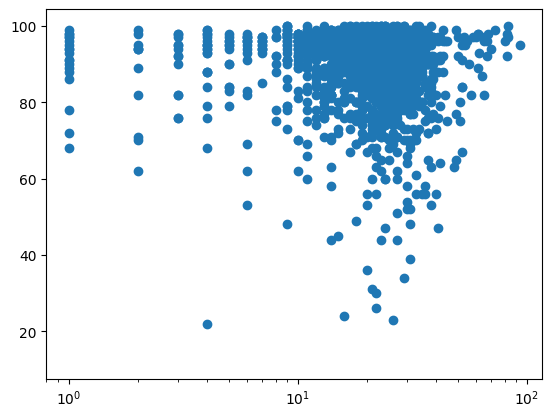

In [177]:
plt.scatter(competency_quizzes_df['Competency_quiz_cumsum_14'].dt.days, competency_quizzes_df['average_quiz_score'])
plt.xscale('log')

In [180]:
submit_cols = [
    f'Competency_quiz_submit_{i}'
    for i in range(1, 15)
]

# Keep students who completed all 14 quizzes.
finishers_df = competency_quizzes_df[
    competency_quizzes_df[submit_cols].notna().all(axis=1)
].copy()

# Calculate days from enrollment to the final quiz.
finishers_df['days_to_finish_quizzes'] = (
    finishers_df['Competency_quiz_cumsum_14'].dt.total_seconds()
    / 86400
)

# Calculate completion-time percentiles within each batch.
percentiles = [0.05, 0.10, 0.25, 0.50]

batch_thresholds = (
    finishers_df
    .groupby('batch_id')['days_to_finish_quizzes']
    .quantile(percentiles)
    .unstack()
)

batch_thresholds.columns = [
    f'p{int(p * 100)}_days'
    for p in batch_thresholds.columns
]

batch_thresholds = batch_thresholds.reset_index()

In [181]:
finishers_df = finishers_df.merge(
    batch_thresholds,
    on='batch_id',
    how='left'
)

for percentile in [5, 10, 25]:
    threshold_col = f'p{percentile}_days'
    flag_col = f'fastest_{percentile}pct'

    finishers_df[flag_col] = (
        finishers_df['days_to_finish_quizzes']
        <= finishers_df[threshold_col]
    )

In [186]:
import pandas as pd

percentiles = range(0, 20, 1)

sensitivity_results = []

for percentile in percentiles:
    threshold_col = f'p{percentile}_days'

    # Calculate the threshold within each batch.
    batch_threshold = (
        finishers_df
        .groupby('batch_id')['days_to_finish_quizzes']
        .quantile(percentile / 100)
    )

    # Map each batch's threshold to its students.
    threshold = finishers_df['batch_id'].map(batch_threshold)

    flagged = finishers_df[
        finishers_df['days_to_finish_quizzes'] <= threshold
    ]

    sensitivity_results.append({
        'percentile': percentile,
        'threshold_median_days': batch_threshold.median(),
        'students_flagged': flagged['student_id'].nunique(),
        'pct_students_flagged': (
            flagged['student_id'].nunique()
            / finishers_df['student_id'].nunique()
            * 100
        ),
        'flagged_median_score': flagged['average_quiz_score'].median(),
        'other_median_score': finishers_df.loc[
            ~finishers_df.index.isin(flagged.index),
            'average_quiz_score'
        ].median()
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

sensitivity_df

,percentile,threshold_median_days,students_flagged,pct_students_flagged,flagged_median_score,other_median_score
0,0,4.000,89,4.787520,94.0,93.0
1,1,5.670,89,4.787520,94.0,93.0
2,2,7.690,91,4.895105,94.0,93.0
3,3,9.000,120,6.455083,94.0,93.0
4,4,9.840,137,7.369554,94.0,93.0
5,5,10.675,171,9.198494,94.0,93.0
6,6,11.470,183,9.844002,94.0,93.0
7,7,12.090,202,10.866057,94.0,92.0
8,8,12.640,219,11.780527,94.0,92.0
9,9,13.000,237,12.748790,94.0,92.0
